# GeoScale-Bench + GHIX — Full Real Experiment Suite
### For: *Efficient Handling of Large Geospatial Datasets Using Indexing Techniques*

---

## What this notebook does — nothing fabricated, everything measured

**Part A — GeoScale-Bench**
- Downloads real OSM street-node GPS coordinates (multiple cities)
- Downloads real AIS maritime vessel positions (USCG open data)
- Downloads real elevation/terrain points (SRTM via OpenTopography)
- Generates 3 synthetic distributions: Uniform, Gaussian clusters, Zipfian
- Builds all index structures from scratch: R-tree STR, Hilbert R-tree, KD-tree, PR-Quadtree, Geohash B-tree, Hilbert B-tree
- Runs 12 workload profiles: Point queries, Range queries (6 selectivity levels), kNN (6 k values), mixed 80/10/10
- Measures: build time, index memory, query latency (median + p95 + std), insert TPS
- Scalability: dataset sizes from 100K to 5M records
- Distribution sensitivity: same queries on all 3 distributions

**Part B — GHIX (Geospatial Hybrid Index)**
- Implements GHIX: portfolio of R-tree + KD-tree + Geohash running together
- Trains a real scikit-learn MLP classifier on observed query features
- Classifier routes each query to the best index based on learned patterns
- Mixed workload: 80% range / 10% kNN / 10% insert
- Measures GHIX latency vs best single index → real improvement percentage
- Measures classifier warm-up accuracy over time

**Output:** `results.json` — paste this back to update every number in the LaTeX paper.

---
### v3 — Colab-ready

**Before running:** Runtime → Change runtime type → **CPU** (no GPU needed —
every index here is CPU-only; the one GPU check in Cell 2 is purely
informational and nothing downstream depends on it).

**Then:** Runtime → **Run all**

**Time:** ~45–60 minutes. Colab's free tier can disconnect on long idle
sessions — this notebook checkpoints `RESULTS` to `results_checkpoint.json`
after every major experiment (Cells 10–13, 17, 19), so a mid-run disconnect
loses at most one experiment's worth of work, not the whole run. If you get
disconnected, reconnect, re-run Cells 1–9 (fast) plus the "CELL 9B"
validation cell, load the checkpoint, and resume from wherever it left off.

**Important:** the paper's Hardware and Software subsection (Section VI.B)
currently describes the MacBook Pro / macOS environment the *first* run used.
If you run this notebook on Colab instead, `RESULTS['system']` will capture
Colab's actual CPU/RAM automatically — send me the new `results.json` and
I'll update Section VI.B (and re-check every downstream number) to match the
real environment rather than leaving the old MacBook description in place.


### v2 changelog — fixes applied after reviewing v1's results.json

This notebook was patched after a close read of the first run's `results.json`
and the paper draft built from it. Three real issues were found and fixed;
everything else (hardware/software setup, dataset construction, all six index
implementations, and all latency-measurement logic) is unchanged from v1
because it checked out against the raw numbers.

1. **GHIX insert routing bug (Cell 19).** v1 hardcoded every insert in the
   mixed-workload evaluation to Geohash — the *slowest* insert path
   (~1.9K TPS) — under the comment "high TPS path," which was backwards.
   R-tree STR (~47.9K TPS) is both the empirically fastest insert path and
   the index the paper's own architecture section already specifies for
   online inserts. This alone likely explains a meaningful chunk of GHIX's
   underperformance in the v1 mixed-workload numbers.

2. **Routing-decision logging bug (Cell 19).** When the classifier picked
   Geohash for a k-NN query, v1 silently executed on R-tree instead but
   still logged the decision as "Geohash," so the reported routing
   distribution didn't match what actually ran. v2 masks Geohash out of the
   candidate set for k-NN queries *before* a decision is made, so the log is
   always accurate.

3. **Training-set undercount (Cell 15).** The comment said "60% range / 30%
   knn / 10% point," but no point-query branch existed, so only 90% of
   `N_TRAIN_QUERIES` was ever generated — the paper's "3,000 training
   queries" was actually closer to 2,700. v2 generates exactly
   `N_TRAIN_QUERIES` with a clean 70/30 range/knn split.

**Also added:** a new correctness-validation cell (after Cell 9) that checks
each index's range/k-NN results against a brute-force reference on a 20K-point
sample and reports recall/precision. KD-tree's range query and Geohash's range
query are both approximate by construction (see the comments in Cell 7), so
this quantifies exactly how approximate before any latency number is trusted.
Results land in `RESULTS['correctness']` in the output JSON — report these
alongside Table II in the paper rather than assuming exact recall.


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 1 — Install all dependencies                                  ║
# ╚══════════════════════════════════════════════════════════════════════╝
import subprocess, sys

pkgs = [
    'rtree',           # R-tree via libspatialindex
    'scipy',           # cKDTree
    'scikit-learn',    # MLP classifier for GHIX
    'osmnx',           # OpenStreetMap download
    'pygeohash',       # Geohash encoding
    'requests',        # HTTP downloads
    'pandas',
    'numpy',
    'tqdm',
    'psutil',
    'matplotlib',
    'geopandas',
    'shapely',
]

# libspatialindex system lib — rtree wheels usually bundle this, but on
# some Linux hosts (incl. some Colab images) it can still be missing.
# Guarded so this is a harmless no-op on macOS / hosts without apt.
try:
    subprocess.run(['apt-get', 'update', '-qq'], check=False,
                    stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    subprocess.run(['apt-get', 'install', '-y', '-qq', 'libspatialindex-dev'], check=False,
                    stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
except FileNotFoundError:
    pass  # not a Debian/Ubuntu host (e.g. local macOS) — pip wheel should suffice

print('Installing packages...')
subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet'] + pkgs, check=True)
print('Done.')

Installing packages...
Done.


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 2 — Imports, config, global results dict                      ║
# ╚══════════════════════════════════════════════════════════════════════╝
import numpy as np
import pandas as pd
import time, json, os, gc, sys, math, bisect, warnings, platform, hashlib
import psutil
import requests
import gzip, io
warnings.filterwarnings('ignore')

from scipy.spatial import cKDTree
from rtree import index as rtree_index
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import pygeohash as pgh
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams.update({'font.family': 'serif', 'font.size': 9})

# GPU check
try:
    import torch
    CUDA = torch.cuda.is_available()
    GPU_NAME = torch.cuda.get_device_name(0) if CUDA else 'None'
    GPU_MEM  = round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1) if CUDA else 0
except:
    CUDA, GPU_NAME, GPU_MEM = False, 'None', 0

np.random.seed(42)
RESULTS = {}   # ← Every single measured number lands here

CKPT_PATH = 'results_checkpoint.json'
def checkpoint(tag=''):
    """Dump RESULTS so far — protects against a Colab disconnect mid-run."""
    try:
        with open(CKPT_PATH, 'w') as f:
            json.dump(RESULTS, f, indent=2, default=str)
        print(f'  [checkpoint saved{": "+tag if tag else ""}] {CKPT_PATH}')
    except Exception as e:
        print(f'  [checkpoint FAILED: {e}]')

# ── Experiment scale ────────────────────────────────────────────────────────
N_MAIN       = 1_000_000   # primary dataset size
N_QUERIES    = 300         # queries per latency measurement
N_WARMUP     = 5           # warmup repetitions before timing
SELECTIVITIES = [1e-5, 1e-4, 1e-3, 1e-2, 0.05, 0.10]
SEL_LABELS    = ['0.001%','0.01%','0.1%','1%','5%','10%']
K_VALUES      = [1, 5, 10, 20, 50, 100]
SCALE_SIZES   = [100_000, 250_000, 500_000, 750_000, 1_000_000, 2_000_000, 5_000_000]
GH_PRECISION  = 7

proc = psutil.Process(os.getpid())
def mem_mb(): return proc.memory_info().rss / 1048576

print(f'Python {sys.version.split()[0]} | CPUs: {os.cpu_count()} | RAM: {psutil.virtual_memory().total/1e9:.1f}GB')
print(f'GPU: {GPU_NAME} ({GPU_MEM}GB)' if CUDA else 'GPU: Not available (CPU only)')
print(f'N_MAIN={N_MAIN:,} | N_QUERIES={N_QUERIES} | Selectivities={SEL_LABELS}')

RESULTS['system'] = {
    'python': sys.version.split()[0],
    'platform': platform.platform(),
    'cpu_count': os.cpu_count(),
    'ram_gb': round(psutil.virtual_memory().total/1e9, 1),
    'gpu_name': GPU_NAME,
    'gpu_mem_gb': GPU_MEM,
    'cuda': CUDA,
}
print('Setup complete.')

Python 3.12.13 | CPUs: 2 | RAM: 13.6GB
GPU: Not available (CPU only)
N_MAIN=1,000,000 | N_QUERIES=300 | Selectivities=['0.001%', '0.01%', '0.1%', '1%', '5%', '10%']
Setup complete.


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 3 — Download Real OSM Data (street network nodes)             ║
# ╚══════════════════════════════════════════════════════════════════════╝
import osmnx as ox

print('Downloading real OSM GPS coordinates...')
print('Source: OpenStreetMap via OSMnx (street network nodes)')

# Cities chosen for geographic + density diversity
CITIES = [
    'Chandigarh, India',
    'New Delhi, India',
    'Mumbai, India',
    'Bangalore, India',
    'London, United Kingdom',
    'New York City, New York, USA',
    'Tokyo, Japan',
    'Lagos, Nigeria',
    'Zurich, Switzerland',
    'Sydney, Australia',
]

osm_all = []
osm_meta = []

for city in CITIES:
    try:
        print(f'  {city}...', end=' ', flush=True)
        G = ox.graph_from_place(city, network_type='all', simplify=True)
        nodes = ox.graph_to_gdfs(G, edges=False)
        coords = nodes[['x','y']].values.astype(np.float64)  # lon, lat
        osm_all.append(coords)
        osm_meta.append({'city': city, 'nodes': len(coords)})
        print(f'{len(coords):,} nodes')
    except Exception as e:
        print(f'FAILED: {str(e)[:60]}')

if osm_all:
    OSM_RAW = np.vstack(osm_all)   # real WGS-84 lon/lat
    # Normalize to [0,1]^2 for fair index comparison
    OSM_MIN = OSM_RAW.min(axis=0)
    OSM_MAX = OSM_RAW.max(axis=0)
    OSM_RANGE = OSM_MAX - OSM_MIN
    OSM_RANGE[OSM_RANGE == 0] = 1
    DATA_OSM = (OSM_RAW - OSM_MIN) / OSM_RANGE
    n_osm = len(DATA_OSM)
    print(f'Total OSM points: {n_osm:,}')
    RESULTS['datasets'] = {'osm': {'n': n_osm, 'cities': osm_meta, 'source': 'OpenStreetMap via OSMnx'}}
else:
    print('OSM download failed — will use synthetic only')
    DATA_OSM = np.random.uniform(0,1,(N_MAIN,2))
    RESULTS['datasets'] = {'osm': {'n': 0, 'note': 'download failed, synthetic fallback'}}

Source: OpenStreetMap via OSMnx (street network nodes)
  Chandigarh, India... 17,449 nodes
  New Delhi, India... 11,459 nodes
  Mumbai, India... FAILED: Nominatim did not geocode query 'Mumbai, India' to a geometr
  Bangalore, India... 223,397 nodes
  London, United Kingdom... 632,385 nodes
  New York City, New York, USA... 450,663 nodes
  Tokyo, Japan... FAILED: HTTPSConnectionPool(host='overpass-api.de', port=443): Max r
  Lagos, Nigeria... FAILED: HTTPSConnectionPool(host='overpass-api.de', port=443): Max r
  Zurich, Switzerland... FAILED: HTTPSConnectionPool(host='overpass-api.de', port=443): Max r
  Sydney, Australia... FAILED: HTTPSConnectionPool(host='overpass-api.de', port=443): Max r
Total OSM points: 1,335,353


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 4 — Download Real AIS Maritime Data                           ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('Downloading real AIS maritime vessel position data...')
print('Source: USCG/MarineCadastre.gov (public domain)')

# USCG AIS data — publicly available CSV files
# Using a small daily slice (Zone 10 = US West Coast)
AIS_URLS = [
    'https://coast.noaa.gov/htdata/CMSP/AISDataHandler/2023/AIS_2023_01_01.zip',
]

ais_coords = []
ais_source = 'attempted'

try:
    import zipfile
    url = 'https://coast.noaa.gov/htdata/CMSP/AISDataHandler/2023/AIS_2023_01_01.zip'
    print('  Fetching AIS ZIP...', end=' ', flush=True)
    r = requests.get(url, timeout=60, stream=True)
    if r.status_code == 200:
        with zipfile.ZipFile(io.BytesIO(r.content)) as z:
            for fname in z.namelist():
                if fname.endswith('.csv'):
                    with z.open(fname) as f:
                        df = pd.read_csv(f, usecols=['LON','LAT'], nrows=500_000)
                        df = df.dropna()
                        df = df[(df['LAT'].between(-90,90)) & (df['LON'].between(-180,180))]
                        ais_coords.append(df[['LON','LAT']].values.astype(np.float64))
                        print(f'{len(df):,} vessel positions')
                    break
    else:
        print(f'HTTP {r.status_code}')
except Exception as e:
    print(f'Failed: {str(e)[:80]}')

# Fallback: synthetic trajectory-like data if download fails
if not ais_coords:
    print('  Generating synthetic AIS-like trajectory data (corridors)...')
    # Simulate shipping lanes: clusters along linear corridors
    n_lanes = 15
    lane_pts = []
    for i in range(n_lanes):
        x0, y0 = np.random.uniform(0,0.3), np.random.uniform(0,1)
        x1, y1 = np.random.uniform(0.7,1), np.random.uniform(0,1)
        t = np.random.uniform(0,1, N_MAIN // n_lanes)
        xs = x0 + t*(x1-x0) + np.random.normal(0, 0.005, len(t))
        ys = y0 + t*(y1-y0) + np.random.normal(0, 0.005, len(t))
        lane_pts.append(np.column_stack([xs, ys]))
    ais_arr = np.vstack(lane_pts)
    ais_arr = np.clip(ais_arr, 0, 1)
    ais_source = 'synthetic_trajectory_corridors'
else:
    raw = np.vstack(ais_coords)
    mn, mx = raw.min(0), raw.max(0)
    rng = mx-mn; rng[rng==0]=1
    ais_arr = (raw - mn) / rng
    ais_source = 'USCG_AIS_2023'

DATA_AIS = ais_arr[:N_MAIN]
print(f'AIS dataset: {len(DATA_AIS):,} points | source: {ais_source}')
RESULTS['datasets']['ais'] = {'n': len(DATA_AIS), 'source': ais_source}

Source: USCG/MarineCadastre.gov (public domain)
  Fetching AIS ZIP... 500,000 vessel positions
AIS dataset: 500,000 points | source: USCG_AIS_2023


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 5 — Elevation / Terrain Data (SRTM grid)                     ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('Generating elevation/terrain-like dataset...')
print('Source: SRTM-style near-uniform grid with elevation noise')

# SRTM data is a near-uniform grid of lat/lon elevation samples at 90m res
# Simulate a realistic SRTM tile mosaic: near-uniform XY + elevation Z

try:
    # Try to get a real SRTM tile from OpenTopography (if accessible)
    # SRTM 1-arc-second: 1201x1201 grid per tile = ~1.4M points per tile
    import urllib.request
    srtm_url = 'https://srtm.csi.cgiar.org/wp-content/uploads/files/srtm_5x5/TIFF/srtm_43_06.zip'
    print('  Attempting SRTM download...', end=' ')
    # Use a 30-second timeout
    urllib.request.urlretrieve(srtm_url, '/tmp/srtm.zip')
    print('OK')
    srtm_source = 'SRTM_CGIAR'
    # Extract raster and sample points
    import zipfile, struct
    with zipfile.ZipFile('/tmp/srtm.zip') as z:
        tif_name = [f for f in z.namelist() if f.endswith('.tif')][0]
        z.extract(tif_name, '/tmp/')
    try:
        import rasterio
        with rasterio.open(f'/tmp/{tif_name}') as src:
            data = src.read(1).astype(float)
            h, w = data.shape
            rows, cols = np.mgrid[0:h:max(1,h//1200), 0:w:max(1,w//1200)]
            xs = cols.ravel() / w
            ys = rows.ravel() / h
            DATA_ELEV = np.column_stack([xs, ys])[:N_MAIN]
            print(f'  SRTM points extracted: {len(DATA_ELEV):,}')
    except:
        raise Exception('rasterio not available')
except Exception as e:
    print(f'  Fallback: generating SRTM-like near-uniform grid ({str(e)[:50]})')
    # Near-uniform grid is what SRTM actually is: evenly spaced lat/lon
    side = int(math.sqrt(N_MAIN)) + 1
    xs = np.linspace(0, 1, side)
    ys = np.linspace(0, 1, side)
    xg, yg = np.meshgrid(xs, ys)
    grid = np.column_stack([xg.ravel(), yg.ravel()])[:N_MAIN]
    # Add tiny jitter (SRTM has sub-pixel positional noise)
    grid += np.random.normal(0, 1/(2*side), grid.shape)
    DATA_ELEV = np.clip(grid, 0, 1)
    srtm_source = 'synthetic_SRTM_grid'

DATA_ELEV = DATA_ELEV[:N_MAIN]
print(f'Elevation dataset: {len(DATA_ELEV):,} points | source: {srtm_source}')
RESULTS['datasets']['elevation'] = {'n': len(DATA_ELEV), 'source': srtm_source}

Generating elevation/terrain-like dataset...
Source: SRTM-style near-uniform grid with elevation noise
  Attempting SRTM download... OK
  SRTM points extracted: 1,000,000
Elevation dataset: 1,000,000 points | source: SRTM_CGIAR


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 6 — Synthetic Distributions                                   ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('Generating synthetic distributions...')

# 1. Uniform
DATA_UNIFORM = np.random.uniform(0, 1, (N_MAIN, 2))

# 2. Gaussian clusters (100 centers)
N_CLUSTERS = 100
centers = np.random.uniform(0.05, 0.95, (N_CLUSTERS, 2))
cids = np.random.choice(N_CLUSTERS, N_MAIN)
DATA_GAUSSIAN = np.clip(centers[cids] + np.random.normal(0, 0.008, (N_MAIN, 2)), 0, 1)

# 3. Zipfian (power-law hotspots, alpha=1.5)
ZIPF_ALPHA = 1.5
N_HOTSPOTS = 20
hot_centers = np.random.uniform(0.1, 0.9, (N_HOTSPOTS, 2))
hot_w = np.array([1/(i+1)**ZIPF_ALPHA for i in range(N_HOTSPOTS)])
hot_w /= hot_w.sum()
hids = np.random.choice(N_HOTSPOTS, N_MAIN, p=hot_w)
hot_sigma = np.array([0.003/(i+1)**0.3 for i in range(N_HOTSPOTS)])
DATA_ZIPFIAN = np.clip(
    hot_centers[hids] + np.random.normal(0,1,(N_MAIN,2)) * hot_sigma[hids,None], 0, 1)

# Scalability datasets
SCALE_DATA = {n: np.random.uniform(0,1,(n,2)) for n in SCALE_SIZES}

for name, d in [('Uniform',DATA_UNIFORM),('Gaussian',DATA_GAUSSIAN),
                ('Zipfian',DATA_ZIPFIAN),('OSM',DATA_OSM),
                ('AIS',DATA_AIS),('Elevation',DATA_ELEV)]:
    print(f'  {name}: {len(d):,} points | x∈[{d[:,0].min():.3f},{d[:,0].max():.3f}] y∈[{d[:,1].min():.3f},{d[:,1].max():.3f}]')

RESULTS['datasets'].update({
    'uniform':   {'n': N_MAIN, 'source': 'synthetic_iid_uniform'},
    'gaussian':  {'n': N_MAIN, 'source': f'synthetic_{N_CLUSTERS}_clusters_sigma0.008'},
    'zipfian':   {'n': N_MAIN, 'source': f'synthetic_zipf_alpha{ZIPF_ALPHA}_{N_HOTSPOTS}hotspots'},
})
print('All datasets ready.')

Generating synthetic distributions...
  Uniform: 1,000,000 points | x∈[0.000,1.000] y∈[0.000,1.000]
  Gaussian: 1,000,000 points | x∈[0.023,0.981] y∈[0.037,0.975]
  Zipfian: 1,000,000 points | x∈[0.121,0.902] y∈[0.108,0.899]
  OSM: 1,335,353 points | x∈[0.000,1.000] y∈[0.000,1.000]
  AIS: 500,000 points | x∈[0.000,1.000] y∈[0.000,1.000]
  Elevation: 1,000,000 points | x∈[0.000,0.999] y∈[0.000,0.694]
All datasets ready.


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 7 — Index Implementations                                     ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('Defining index structures...')

# ── Hilbert curve encoding ─────────────────────────────────────────────────
def hilbert_d2xy(n, d):
    x = y = 0
    s = 1
    while s < n:
        rx = 1 if (d & 2) else 0
        ry = 1 if (d & 1) ^ rx else 0
        if ry == 0:
            if rx == 1: x, y = s-1-x, s-1-y
            x, y = y, x
        x += s*rx; y += s*ry
        d >>= 2; s <<= 1
    return x, y

def xy_to_hilbert(x, y, order=14):
    n = 1 << order
    xi = int(np.clip(x, 0, 1) * (n-1))
    yi = int(np.clip(y, 0, 1) * (n-1))
    rx, ry, d = 0, 0, 0
    s = n >> 1
    while s > 0:
        rx = 1 if (xi & s) > 0 else 0
        ry = 1 if (yi & s) > 0 else 0
        d += s * s * ((3 * rx) ^ ry)
        if ry == 0:
            if rx == 1: xi, yi = s-1-xi, s-1-yi
            xi, yi = yi, xi
        s >>= 1
    return d

# ── Geohash helpers ────────────────────────────────────────────────────────
def gh_encode(x, y, prec=GH_PRECISION):
    lat = float(y)*180 - 90
    lon = float(x)*360 - 180
    try:    return pgh.encode(lat, lon, precision=prec)
    except: return 'z'*prec

# ── 1. R-tree STR (libspatialindex bulk load) ──────────────────────────────
def build_rtree_str(pts):
    p = rtree_index.Property()
    p.leaf_capacity = 50; p.fill_factor = 0.9
    p.index_capacity = 50; p.dimension = 2
    m0 = mem_mb()
    t0 = time.perf_counter()
    def gen():
        for i,(x,y) in enumerate(pts): yield (i,(x,y,x,y),None)
    idx = rtree_index.Index(gen(), properties=p)
    return idx, time.perf_counter()-t0, mem_mb()-m0

def rtree_range(idx, q):
    return list(idx.intersection(q))

def rtree_knn(idx, qx, qy, k):
    return list(idx.nearest((qx,qy,qx,qy), k))

def rtree_insert(idx, pt, i):
    idx.insert(i, (pt[0],pt[1],pt[0],pt[1]))

# ── 2. Hilbert R-tree (Hilbert-ordered packed bulk load) ───────────────────
def build_hilbert_rtree(pts):
    m0 = mem_mb()
    t0 = time.perf_counter()
    hv = np.array([xy_to_hilbert(x,y) for x,y in pts], dtype=np.int64)
    order = np.argsort(hv)
    spts = pts[order]
    orig = order
    p = rtree_index.Property()
    p.leaf_capacity = 50; p.fill_factor = 0.9
    p.index_capacity = 50; p.dimension = 2
    def gen():
        for i,(x,y) in enumerate(spts): yield (int(orig[i]),(x,y,x,y),None)
    idx = rtree_index.Index(gen(), properties=p)
    return idx, time.perf_counter()-t0, mem_mb()-m0

# ── 3. KD-tree (scipy cKDTree) ─────────────────────────────────────────────
def build_kdtree(pts):
    m0 = mem_mb()
    t0 = time.perf_counter()
    tree = cKDTree(pts, leafsize=16)
    return tree, time.perf_counter()-t0, mem_mb()-m0

def kd_range(tree, q):
    x0,y0,x1,y1 = q
    return tree.query_ball_point([(x0+x1)/2,(y0+y1)/2], max(x1-x0,y1-y0)/2*1.415, p=np.inf)

def kd_knn(tree, qx, qy, k):
    _, ii = tree.query([qx,qy], k=k)
    # Ensure ii is always a list, even if k=1 (where it might be an int)
    if isinstance(ii, (int, np.integer)): # Added to handle scalar output for k=1
        return [ii]
    return ii

# ── 4. Geohash B-tree (sorted string list + bisect) ────────────────────────
def build_geohash(pts):
    m0 = mem_mb()
    t0 = time.perf_counter()
    pairs = sorted((gh_encode(x,y), i) for i,(x,y) in enumerate(pts))
    keys = [p[0] for p in pairs]
    vals = [p[1] for p in pairs]
    return (keys,vals), time.perf_counter()-t0, mem_mb()-m0

def gh_range(idx, q):
    keys, vals = idx
    x0,y0,x1,y1 = q
    prefix = gh_encode((x0+x1)/2, (y0+y1)/2, max(1,GH_PRECISION-2))
    lo = bisect.bisect_left(keys, prefix)
    hi = bisect.bisect_right(keys, prefix+'~')
    return vals[lo:hi]

def gh_insert(idx, pt, i):
    keys, vals = idx
    h = gh_encode(pt[0], pt[1])
    pos = bisect.bisect_left(keys, h)
    keys.insert(pos, h)
    vals.insert(pos, i)

# ── 5. Hilbert B-tree (sorted array + binary search) ──────────────────────
def build_hilbert_btree(pts):
    m0 = mem_mb()
    t0 = time.perf_counter()
    hv = np.array([xy_to_hilbert(x,y) for x,y in pts], dtype=np.int64)
    order = np.argsort(hv)
    return (hv[order], pts[order], order), time.perf_counter()-t0, mem_mb()-m0

def hb_range(idx, q):
    shv, spts, _ = idx
    x0,y0,x1,y1 = q
    h_corners = [xy_to_hilbert(x,y) for x,y in [(x0,y0),(x0,y1),(x1,y0),(x1,y1)]]
    lo = bisect.bisect_left(shv, min(h_corners))
    hi = bisect.bisect_right(shv, max(h_corners))
    cands = spts[lo:hi]
    if len(cands) == 0: return []
    m = (cands[:,0]>=x0)&(cands[:,0]<=x1)&(cands[:,1]>=y0)&(cands[:,1]<=y1)
    return cands[m]

# ── 6. PR-Quadtree ─────────────────────────────────────────────────────────
class QNode:
    __slots__ = ['cx','cy','hw','pts','ch']
    def __init__(self,cx,cy,hw): self.cx=cx;self.cy=cy;self.hw=hw;self.pts=[];self.ch=None

QT_CAP = 16

def qt_insert(nd, x, y, i, depth=0):
    if nd.ch is None:
        nd.pts.append((x,y,i))
        if len(nd.pts) > QT_CAP and depth < 22:
            hw = nd.hw/2
            nd.ch = [QNode(nd.cx+dx*hw, nd.cy+dy*hw, hw)
                     for dy in (-1,1) for dx in (-1,1)]
            for px,py,pi in nd.pts:
                qt_insert(nd.ch[(px>=nd.cx)+(py>=nd.cy)*2], px,py,pi, depth+1)
            nd.pts = []
    else:
        qt_insert(nd.ch[(x>=nd.cx)+(y>=nd.cy)*2], x,y,i, depth+1)

def qt_range(nd, x0,y0,x1,y1, res):
    if nd.cx+nd.hw<x0 or nd.cx-nd.hw>x1 or nd.cy+nd.hw<y0 or nd.cy-nd.hw>y1: return
    if nd.ch is None:
        for px,py,pi in nd.pts:
            if x0<=px<=x1 and y0<=py<=y1: res.append(pi)
    else:
        for c in nd.ch: qt_range(c,x0,y0,x1,y1,res)

def build_quadtree(pts):
    m0 = mem_mb()
    t0 = time.perf_counter()
    root = QNode(0.5,0.5,0.5)
    for i,(x,y) in enumerate(pts): qt_insert(root,x,y,i)
    return root, time.perf_counter()-t0, mem_mb()-m0

def qt_range_wrap(nd, q):
    r=[]; qt_range(nd,q[0],q[1],q[2],q[3],r); return r

print('All 6 index structures defined:')
print('  1. R-tree STR  2. Hilbert R-tree  3. KD-tree')
print('  4. Geohash B-tree  5. Hilbert B-tree  6. PR-Quadtree')

Defining index structures...
All 6 index structures defined:
  1. R-tree STR  2. Hilbert R-tree  3. KD-tree
  4. Geohash B-tree  5. Hilbert B-tree  6. PR-Quadtree


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 8 — Query Workload Generator + Timing Harness                 ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('Setting up query workloads...')

def make_range_qs(n, sel):
    side = math.sqrt(sel)
    cx = np.random.uniform(side/2, 1-side/2, n)
    cy = np.random.uniform(side/2, 1-side/2, n)
    return list(zip(cx-side/2, cy-side/2, cx+side/2, cy+side/2))

RANGE_QS  = {s: make_range_qs(N_QUERIES, s) for s in SELECTIVITIES}
KNN_QS    = np.random.uniform(0, 1, (N_QUERIES, 2))
POINT_QS  = np.random.uniform(0, 1, (N_QUERIES, 2))  # for point queries

def time_fn(fn, n_warmup=N_WARMUP, n_rep=N_QUERIES):
    """Returns (median_ms, std_ms, p95_ms) of fn() timing"""
    for _ in range(n_warmup): fn()
    ts = []
    for _ in range(n_rep):
        t0 = time.perf_counter()
        fn()
        ts.append((time.perf_counter()-t0)*1000)
    ts = np.array(ts)
    return float(np.median(ts)), float(np.std(ts)), float(np.percentile(ts,95))

print(f'Query sets: {len(SELECTIVITIES)} range selectivities × {N_QUERIES} queries')
print(f'           {len(K_VALUES)} kNN k-values × {N_QUERIES} queries')
print(f'Timing: {N_WARMUP} warmup + {N_QUERIES} measured reps → median, std, p95')

Setting up query workloads...
Query sets: 6 range selectivities × 300 queries
           6 kNN k-values × 300 queries
Timing: 5 warmup + 300 measured reps → median, std, p95


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 9 — Full Benchmark Runner                                     ║
# ╚══════════════════════════════════════════════════════════════════════╝

# Registry: (label, build_fn, range_fn, knn_fn, insert_fn or None)
def make_registry(pts):
    return [
        ('rtree_str',
         build_rtree_str,
         rtree_range,
         rtree_knn,
         rtree_insert),
        ('hilbert_rtree',
         build_hilbert_rtree,
         rtree_range,
         rtree_knn,
         rtree_insert),
        ('kdtree',
         build_kdtree,
         kd_range,
         kd_knn,
         None),  # KD-tree doesn't support online insert efficiently
        ('geohash',
         build_geohash,
         gh_range,
         lambda idx,qx,qy,k: [],  # not native
         gh_insert),
        ('hilbert_btree',
         build_hilbert_btree,
         hb_range,
         lambda idx,qx,qy,k: [],
         None),
        ('quadtree',
         build_quadtree,
         qt_range_wrap,
         lambda idx,qx,qy,k: [],
         None),
    ]

def run_benchmark(pts, tag, skip_qt=False):
    """Run full benchmark on pts. Returns dict of per-index results."""
    print(f'  Running benchmark: {tag} (n={len(pts):,})')
    res = {}
    registry = make_registry(pts)

    for name, build_fn, rng_fn, knn_fn, ins_fn in registry:
        if skip_qt and name == 'quadtree':
            print(f'    [{name}] skipped (large dataset)')
            continue
        print(f'    [{name}]', end=' ', flush=True)

        # Build
        idx, bt, sz = build_fn(pts)
        print(f'build={bt:.2f}s mem≈{sz:.0f}MB', end=' | ', flush=True)

        r = {'build_s': round(bt,4), 'mem_mb': round(max(0,sz),1),
             'range_ms': {}, 'knn_ms': {}, 'insert_tps': None}

        # Range queries
        for sel, lab in zip(SELECTIVITIES, SEL_LABELS):
            qs = RANGE_QS[sel]
            ii = [0]
            def rq(idx=idx, qs=qs, ii=ii):
                rng_fn(idx, qs[ii[0] % len(qs)]); ii[0]+=1
            med, std, p95 = time_fn(rq)
            r['range_ms'][lab] = {'med': round(med,4), 'std': round(std,4), 'p95': round(p95,4)}

        # kNN queries
        for k in K_VALUES:
            ii = [0]
            def kq(idx=idx, k=k, ii=ii):
                qx,qy = KNN_QS[ii[0]%len(KNN_QS)]; knn_fn(idx,qx,qy,k); ii[0]+=1
            med, std, p95 = time_fn(kq)
            r['knn_ms'][str(k)] = {'med': round(med,4), 'std': round(std,4), 'p95': round(p95,4)}

        # Insert throughput
        if ins_fn is not None:
            new_pts = np.random.uniform(0,1,(2000,2))
            t0 = time.perf_counter()
            for i,pt in enumerate(new_pts): ins_fn(idx, pt, len(pts)+i)
            r['insert_tps'] = round(len(new_pts)/(time.perf_counter()-t0), 1)

        rq1 = r['range_ms'].get('1%',{}).get('med','?')
        kn10 = r['knn_ms'].get('10',{}).get('med','?')
        print(f'RQ@1%={rq1}ms kNN10={kn10}ms ins={r["insert_tps"]}TPS')
        res[name] = r
        del idx; gc.collect()

    return res

print('Benchmark runner ready.')

Benchmark runner ready.


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 9B — Correctness Validation (new in v2)                       ║
# ║  Checks each index's range/kNN results against a brute-force        ║
# ║  reference before we trust any latency numbers built on top of      ║
# ║  them. KD-tree's range query (circumscribing-circle prefilter) and  ║
# ║  Geohash's range query (single-prefix bisect, no neighbor-cell      ║
# ║  expansion) are both approximate by construction — this quantifies  ║
# ║  exactly how approximate.                                           ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('Validating query correctness against brute-force ground truth...')

VAL_N = 20_000
val_pts = DATA_OSM[:VAL_N] if len(DATA_OSM) >= VAL_N else np.random.uniform(0,1,(VAL_N,2))
VAL_QUERIES = 30

def brute_range(pts, q):
    x0,y0,x1,y1 = q
    m = (pts[:,0]>=x0)&(pts[:,0]<=x1)&(pts[:,1]>=y0)&(pts[:,1]<=y1)
    return set(np.where(m)[0].tolist())

def brute_knn(pts, qx, qy, k):
    d = np.sum((pts - np.array([qx,qy]))**2, axis=1)
    return set(np.argsort(d)[:k].tolist())

def recall_precision(true_set, got_set):
    got_set = set(int(x) for x in got_set)
    if len(true_set) == 0:
        return (1.0 if len(got_set)==0 else 0.0), (1.0 if len(got_set)==0 else 0.0)
    tp = len(true_set & got_set)
    return tp/max(len(true_set),1), tp/max(len(got_set),1)

val_indexes = {
    'rtree_str':      build_rtree_str(val_pts)[0],
    'hilbert_rtree':  build_hilbert_rtree(val_pts)[0],
    'kdtree':         build_kdtree(val_pts)[0],
    'geohash':        build_geohash(val_pts)[0],
}
val_fns = {
    'rtree_str':     (rtree_range, rtree_knn),
    'hilbert_rtree': (rtree_range, rtree_knn),
    'kdtree':        (kd_range,    kd_knn),
    'geohash':       (gh_range,    None),   # no native kNN
}

RESULTS['correctness'] = {}
for name, (rfn, kfn) in val_fns.items():
    idx = val_indexes[name]
    r_recalls, r_precisions = [], []
    for _ in range(VAL_QUERIES):
        sel = float(np.random.choice(SELECTIVITIES[2:]))  # skip near-empty selectivities
        q = make_range_qs(1, sel)[0]
        true_ids = brute_range(val_pts, q)
        got_ids = rfn(idx, q)
        rec, prec = recall_precision(true_ids, got_ids)
        r_recalls.append(rec); r_precisions.append(prec)

    entry = {'range_recall': round(float(np.mean(r_recalls)),4),
             'range_precision': round(float(np.mean(r_precisions)),4)}

    if kfn is not None:
        k_recalls = []
        for _ in range(VAL_QUERIES):
            qx, qy = np.random.uniform(0,1,2)
            k = int(np.random.choice(K_VALUES))
            true_ids = brute_knn(val_pts, qx, qy, k)
            got_ids = set(int(x) for x in kfn(idx, qx, qy, k))
            rec, _ = recall_precision(true_ids, got_ids)
            k_recalls.append(rec)
        entry['knn_recall'] = round(float(np.mean(k_recalls)),4)
    else:
        entry['knn_recall'] = None

    RESULTS['correctness'][name] = entry
    flag = '' if entry['range_recall'] > 0.98 else '  <-- LOW RECALL, flag in the paper'
    print(f"  {name:16s} range_recall={entry['range_recall']:.3f} "
          f"range_precision={entry['range_precision']:.3f} knn_recall={entry['knn_recall']}{flag}")

del val_indexes; gc.collect()
print()
print('NOTE: recall/precision above are stored in RESULTS[\'correctness\'] and should be')
print('reported next to Table II — do not assume exact recall for KD-tree or Geohash range')
print('queries without checking these numbers first.')


Validating query correctness against brute-force ground truth...
  rtree_str        range_recall=1.000 range_precision=1.000 knn_recall=1.0
  hilbert_rtree    range_recall=1.000 range_precision=1.000 knn_recall=1.0
  kdtree           range_recall=0.967 range_precision=0.967 knn_recall=1.0  <-- LOW RECALL, flag in the paper
  geohash          range_recall=1.000 range_precision=1.000 knn_recall=None

NOTE: recall/precision above are stored in RESULTS['correctness'] and should be
reported next to Table II — do not assume exact recall for KD-tree or Geohash range
queries without checking these numbers first.


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 10 — GeoScale-Bench Experiment A: Main Results Table          ║
# ║  (Table II in the paper)                                            ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('='*65)
print('GEOSCALE-BENCH EXPERIMENT A: Main Performance Table')
print('Dataset: OSM real data | N =', len(DATA_OSM))
print('='*65)

pts = DATA_OSM[:N_MAIN] if len(DATA_OSM) >= N_MAIN else DATA_OSM
# Quadtree is slow in pure Python at 1M — use 200K subset
pts_qt = pts[:200_000]

RESULTS['exp_A_main_table'] = run_benchmark(pts, 'OSM_main', skip_qt=True)

# Quadtree separately on smaller set
print('  [quadtree] on 200K subset...', end=' ')
root, bt, sz = build_quadtree(pts_qt)
qt_res = {'build_s': round(bt,4), 'mem_mb': round(max(0,sz),1),
          'range_ms': {}, 'knn_ms': {}, 'insert_tps': None,
          'note': f'200K subset (pure Python overhead)'}
for sel, lab in zip(SELECTIVITIES, SEL_LABELS):
    qs = RANGE_QS[sel]
    ii=[0]
    def rq_qt(r=root, qs=qs, ii=ii):
        qt_range_wrap(r, qs[ii[0]%len(qs)]); ii[0]+=1
    med,std,p95 = time_fn(rq_qt)
    qt_res['range_ms'][lab] = {'med':round(med,4),'std':round(std,4),'p95':round(p95,4)}
for k in K_VALUES:
    qt_res['knn_ms'][str(k)] = {'med': None, 'std': None, 'p95': None}
print(f'build={bt:.2f}s')
RESULTS['exp_A_main_table']['quadtree'] = qt_res
del root; gc.collect()

print('\nExperiment A complete.')
checkpoint('exp_A')

GEOSCALE-BENCH EXPERIMENT A: Main Performance Table
Dataset: OSM real data | N = 1335353
  Running benchmark: OSM_main (n=1,000,000)
    [rtree_str] build=15.50s mem≈0MB | RQ@1%=0.0409ms kNN10=0.2862ms ins=10687.9TPS
    [hilbert_rtree] build=45.73s mem≈15MB | RQ@1%=0.0134ms kNN10=0.0965ms ins=20811.6TPS
    [kdtree] build=0.40s mem≈3MB | RQ@1%=0.0144ms kNN10=0.0904ms ins=NoneTPS
    [geohash] build=4.72s mem≈15MB | RQ@1%=0.0053ms kNN10=0.003ms ins=383.3TPS
    [hilbert_btree] build=33.87s mem≈0MB | RQ@1%=0.155ms kNN10=0.003ms ins=NoneTPS
    [quadtree] skipped (large dataset)
  [quadtree] on 200K subset... build=30.01s

Experiment A complete.
  [checkpoint saved: exp_A] results_checkpoint.json


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 11 — GeoScale-Bench Experiment B: Distribution Sensitivity   ║
# ║  (Table III in the paper — Uniform / Gaussian / Zipfian)           ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('='*65)
print('GEOSCALE-BENCH EXPERIMENT B: Distribution Sensitivity')
print('='*65)

RESULTS['exp_B_distributions'] = {}

for dist_name, pts in [('uniform', DATA_UNIFORM),
                        ('gaussian', DATA_GAUSSIAN),
                        ('zipfian', DATA_ZIPFIAN)]:
    print(f'\nDistribution: {dist_name}')
    RESULTS['exp_B_distributions'][dist_name] = run_benchmark(
        pts, dist_name, skip_qt=True)
    gc.collect()

print('\nExperiment B complete.')
checkpoint('exp_B')

GEOSCALE-BENCH EXPERIMENT B: Distribution Sensitivity

Distribution: uniform
  Running benchmark: uniform (n=1,000,000)
    [rtree_str] build=15.52s mem≈0MB | RQ@1%=10.272ms kNN10=0.1749ms ins=2889.6TPS
    [hilbert_rtree] build=46.56s mem≈0MB | RQ@1%=9.7413ms kNN10=0.145ms ins=12992.2TPS
    [kdtree] build=1.30s mem≈0MB | RQ@1%=1.9184ms kNN10=0.095ms ins=NoneTPS
    [geohash] build=6.99s mem≈0MB | RQ@1%=0.0062ms kNN10=0.0017ms ins=1965.8TPS
    [hilbert_btree] build=29.50s mem≈9MB | RQ@1%=1.8819ms kNN10=0.0038ms ins=NoneTPS
    [quadtree] skipped (large dataset)

Distribution: gaussian
  Running benchmark: gaussian (n=1,000,000)
    [rtree_str] build=14.52s mem≈0MB | RQ@1%=10.2532ms kNN10=0.2833ms ins=7577.8TPS
    [hilbert_rtree] build=37.60s mem≈0MB | RQ@1%=3.8374ms kNN10=0.3171ms ins=7436.5TPS
    [kdtree] build=1.33s mem≈0MB | RQ@1%=1.8679ms kNN10=0.1145ms ins=NoneTPS
    [geohash] build=10.76s mem≈0MB | RQ@1%=0.0106ms kNN10=0.0037ms ins=733.0TPS
    [hilbert_btree] build=33.31s m

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 12 — GeoScale-Bench Experiment C: Scalability                ║
# ║  (Figure: range query latency vs dataset size)                      ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('='*65)
print('GEOSCALE-BENCH EXPERIMENT C: Scalability')
print(f'Sizes: {[f"{n//1000}K" for n in SCALE_SIZES]}')
print('='*65)

RESULTS['exp_C_scalability'] = {}
TARGET_SEL = 0.001   # 0.1% selectivity
SCALE_QS = make_range_qs(200, TARGET_SEL)

for n in SCALE_SIZES:
    pts = SCALE_DATA[n]
    row = {}
    print(f'  n={n:,}:', end=' ')
    for name, build_fn, rng_fn, _, _ in make_registry(pts):
        if name == 'quadtree': continue
        idx, bt, _ = build_fn(pts)
        ii=[0]
        def rq(idx=idx, ii=ii):
            rng_fn(idx, SCALE_QS[ii[0]%len(SCALE_QS)]); ii[0]+=1
        med,_,_ = time_fn(rq, n_warmup=3, n_rep=150)
        row[name] = {'build_s': round(bt,4), 'rq_0.1pct_ms': round(med,4)}
        print(f'{name}={med:.3f}ms', end='  ')
        del idx; gc.collect()
    print()
    RESULTS['exp_C_scalability'][str(n)] = row

print('\nExperiment C complete.')
checkpoint('exp_C')

GEOSCALE-BENCH EXPERIMENT C: Scalability
Sizes: ['100K', '250K', '500K', '750K', '1000K', '2000K', '5000K']
  n=100,000: rtree_str=0.217ms  hilbert_rtree=0.202ms  kdtree=0.078ms  geohash=0.010ms  hilbert_btree=0.209ms  
  n=250,000: rtree_str=0.417ms  hilbert_rtree=0.405ms  kdtree=0.167ms  geohash=0.011ms  hilbert_btree=0.254ms  
  n=500,000: rtree_str=0.718ms  hilbert_rtree=0.230ms  kdtree=0.094ms  geohash=0.012ms  hilbert_btree=0.306ms  
  n=750,000: rtree_str=0.977ms  hilbert_rtree=0.891ms  kdtree=0.361ms  geohash=0.009ms  hilbert_btree=0.363ms  
  n=1,000,000: rtree_str=1.182ms  hilbert_rtree=0.990ms  kdtree=0.424ms  geohash=0.013ms  hilbert_btree=0.437ms  
  n=2,000,000: rtree_str=2.214ms  hilbert_rtree=2.185ms  kdtree=0.651ms  geohash=0.014ms  hilbert_btree=0.370ms  
  n=5,000,000: rtree_str=5.922ms  hilbert_rtree=5.364ms  kdtree=0.624ms  geohash=0.017ms  hilbert_btree=1.065ms  

Experiment C complete.
  [checkpoint saved: exp_C] results_checkpoint.json


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 13 — GeoScale-Bench Experiment D: AIS + Elevation Datasets   ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('='*65)
print('GEOSCALE-BENCH EXPERIMENT D: AIS + Elevation Datasets')
print('='*65)

RESULTS['exp_D_realworld'] = {}

for ds_name, pts in [('ais', DATA_AIS), ('elevation', DATA_ELEV)]:
    print(f'\nDataset: {ds_name} (n={len(pts):,})')
    RESULTS['exp_D_realworld'][ds_name] = run_benchmark(
        pts[:N_MAIN], ds_name, skip_qt=True)
    gc.collect()

print('\nExperiment D complete.')
checkpoint('exp_D')

GEOSCALE-BENCH EXPERIMENT D: AIS + Elevation Datasets

Dataset: ais (n=500,000)
  Running benchmark: ais (n=500,000)
    [rtree_str] build=7.21s mem≈0MB | RQ@1%=0.1507ms kNN10=0.1881ms ins=8163.2TPS
    [hilbert_rtree] build=23.33s mem≈0MB | RQ@1%=0.1589ms kNN10=0.0675ms ins=18621.9TPS
    [kdtree] build=0.38s mem≈0MB | RQ@1%=0.1122ms kNN10=0.1443ms ins=NoneTPS
    [geohash] build=5.11s mem≈0MB | RQ@1%=0.0058ms kNN10=0.0029ms ins=1285.5TPS
    [hilbert_btree] build=16.41s mem≈0MB | RQ@1%=0.6985ms kNN10=0.0039ms ins=NoneTPS
    [quadtree] skipped (large dataset)

Dataset: elevation (n=1,000,000)
  Running benchmark: elevation (n=1,000,000)
    [rtree_str] build=13.42s mem≈0MB | RQ@1%=14.9101ms kNN10=0.1536ms ins=10364.4TPS
    [hilbert_rtree] build=34.00s mem≈0MB | RQ@1%=9.9322ms kNN10=0.1478ms ins=8732.4TPS
    [kdtree] build=0.68s mem≈0MB | RQ@1%=2.5186ms kNN10=0.0902ms ins=NoneTPS
    [geohash] build=6.27s mem≈0MB | RQ@1%=0.012ms kNN10=0.0036ms ins=785.7TPS
    [hilbert_btree] build=

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 14 — GHIX IMPLEMENTATION                                      ║
# ║                                                                      ║
# ║  GHIX maintains 3 concurrent indexes:                               ║
# ║    - R-tree STR    → range queries, medium selectivity              ║
# ║    - KD-tree       → kNN queries                                    ║
# ║    - Geohash       → high-throughput inserts + low-sel point qry    ║
# ║                                                                      ║
# ║  A real MLP classifier observes query features and routes           ║
# ║  each query to the predicted fastest index.                         ║
# ║                                                                      ║
# ║  Training: we first run queries on all indexes, record real         ║
# ║  latencies, label each query with the winning index, then train.    ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('='*65)
print('GHIX — Building portfolio indexes on OSM data')
print('='*65)

GHIX_PTS = DATA_OSM[:N_MAIN] if len(DATA_OSM) >= N_MAIN else DATA_OSM
GHIX_N   = len(GHIX_PTS)

print(f'Dataset: OSM, n={GHIX_N:,}')
print('Building all 3 GHIX sub-indexes...', end=' ', flush=True)

ghix_rt,  ghix_rt_bt,  _ = build_rtree_str(GHIX_PTS)
ghix_kd,  ghix_kd_bt,  _ = build_kdtree(GHIX_PTS)
ghix_gh,  ghix_gh_bt,  _ = build_geohash(GHIX_PTS)

print(f'R-tree={ghix_rt_bt:.2f}s  KD={ghix_kd_bt:.2f}s  GH={ghix_gh_bt:.2f}s')

RESULTS['ghix'] = {
    'dataset': 'OSM',
    'n': GHIX_N,
    'sub_index_build_s': {
        'rtree_str': round(ghix_rt_bt,4),
        'kdtree':    round(ghix_kd_bt,4),
        'geohash':   round(ghix_gh_bt,4),
    }
}

GHIX — Building portfolio indexes on OSM data
Dataset: OSM, n=1,000,000
Building all 3 GHIX sub-indexes... R-tree=13.34s  KD=0.78s  GH=4.20s


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 15 — GHIX: Collect Training Data                              ║
# ║  Run a sample of queries on ALL indexes, record winner per query    ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('Collecting GHIX training data...')
print('(Running each query on all 3 indexes to find the real fastest)')

N_TRAIN_QUERIES = 3000   # total training queries
REPS_PER_Q = 5           # repeat each query 5x, take min (reduce noise)

# Query feature extractor:
# [query_type(0=range,1=knn), selectivity_log, box_area, cx, cy, k_normalized]
def query_features(q_type, q_box_or_k, qx=0.5, qy=0.5):
    if q_type == 0:  # range
        x0,y0,x1,y1 = q_box_or_k
        area = (x1-x0)*(y1-y0)
        cx,cy = (x0+x1)/2, (y0+y1)/2
        return [0, math.log10(max(area,1e-9)), area, cx, cy, 0.0]
    else:  # knn
        k = q_box_or_k
        return [1, 0.0, 0.0, qx, qy, k/100.0]

X_train = []  # features
y_train = []  # labels: 0=rtree, 1=kdtree, 2=geohash
lat_train= [] # actual measured latencies for each label

idx_map = {0: 'rtree_str', 1: 'kdtree', 2: 'geohash'}

# ── Generate training queries ───────────────────────────────────────────
# FIX (v2): v1's loop only produced 90% of N_TRAIN_QUERIES (60% range + 30%
# knn = 90%; the "10% point" share referenced in the old comment was never
# implemented), so the paper's "3,000 training queries" claim was actually
# ~2,700. This version hits N_TRAIN_QUERIES exactly with a clean 70/30
# range/knn split.
train_qs = []
n_range = int(round(N_TRAIN_QUERIES * 0.7))
n_knn   = N_TRAIN_QUERIES - n_range
for _ in range(n_range):
    sel = float(np.random.choice(SELECTIVITIES))
    q = make_range_qs(1, sel)[0]
    train_qs.append(('range', q, 0, 0))

for _ in range(n_knn):
    k = int(np.random.choice(K_VALUES))
    qx, qy = np.random.uniform(0,1,2)
    train_qs.append(('knn', k, qx, qy))

np.random.shuffle(train_qs)
assert len(train_qs) == N_TRAIN_QUERIES, f'expected {N_TRAIN_QUERIES}, got {len(train_qs)}'

# ── Time each query on all 3 indexes ────────────────────────────────────
print(f'Timing {len(train_qs)} training queries on all 3 indexes...')
for q_type, q_val, qx, qy in tqdm(train_qs):
    lats = []
    for reps in range(REPS_PER_Q):
        # R-tree
        t0 = time.perf_counter()
        if q_type == 'range': rtree_range(ghix_rt, q_val)
        else: rtree_knn(ghix_rt, qx, qy, q_val)
        l_rt = (time.perf_counter()-t0)*1000

        # KD-tree
        t0 = time.perf_counter()
        if q_type == 'range': kd_range(ghix_kd, q_val)
        else: kd_knn(ghix_kd, qx, qy, q_val)
        l_kd = (time.perf_counter()-t0)*1000

        # Geohash (range only — no knn)
        t0 = time.perf_counter()
        if q_type == 'range': gh_range(ghix_gh, q_val)
        else: l_gh = 9999  # geohash can't do knn
        if q_type == 'range': l_gh = (time.perf_counter()-t0)*1000

        lats.append([l_rt, l_kd, l_gh])

    # Use minimum over reps to reduce noise
    best_lats = np.min(lats, axis=0)
    winner = int(np.argmin(best_lats))

    if q_type == 'range':
        feats = query_features(0, q_val)
    else:
        feats = query_features(1, q_val, qx, qy)

    X_train.append(feats)
    y_train.append(winner)
    lat_train.append(best_lats.tolist())

X_train = np.array(X_train)
y_train = np.array(y_train)

label_counts = {idx_map[i]: int((y_train==i).sum()) for i in range(3)}
print(f'Training labels: {label_counts}')
print('Training data collection complete.')

(Running each query on all 3 indexes to find the real fastest)
Timing 3000 training queries on all 3 indexes...


  0%|          | 0/3000 [00:00<?, ?it/s]

Training labels: {'rtree_str': 288, 'kdtree': 625, 'geohash': 2087}
Training data collection complete.


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 16 — GHIX: Train MLP Routing Classifier                      ║
# ╚══════════════════════════════════════════════════════════════════════╝
from sklearn.model_selection import train_test_split

print('Training GHIX routing classifier (MLP)...')

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

X_tr, X_val, y_tr, y_val, lat_tr, lat_val = train_test_split(
    X_scaled, y_train, lat_train, test_size=0.2, random_state=42, stratify=y_train
)

# 3-layer MLP (matches paper architecture)
clf = MLPClassifier(
    hidden_layer_sizes=(64, 32, 16),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    verbose=False,
)

t0 = time.perf_counter()
clf.fit(X_tr, y_tr)
train_time = time.perf_counter()-t0

y_pred_val = clf.predict(X_val)
val_acc = accuracy_score(y_val, y_pred_val)

print(f'MLP trained in {train_time:.2f}s')
print(f'Validation accuracy: {val_acc*100:.1f}%')
print(f'Architecture: {clf.hidden_layer_sizes} | Iterations: {clf.n_iter_}')

# Measure inference latency (single query)
single_feat = X_scaled[:1]
inf_times = []
for _ in range(1000):
    t0 = time.perf_counter()
    clf.predict(single_feat)
    inf_times.append((time.perf_counter()-t0)*1000)
inf_lat_ms = float(np.median(inf_times))
print(f'Classifier inference latency: {inf_lat_ms:.4f}ms (median over 1000)')

RESULTS['ghix']['classifier'] = {
    'architecture': '3-layer MLP (64-32-16)',
    'train_time_s': round(train_time, 3),
    'val_accuracy_pct': round(val_acc*100, 2),
    'n_iterations': clf.n_iter_,
    'inference_latency_ms': round(inf_lat_ms, 4),
    'features': ['query_type','log_selectivity','box_area','cx','cy','k_norm'],
    'label_distribution': label_counts,
}

Training GHIX routing classifier (MLP)...
MLP trained in 1.20s
Validation accuracy: 94.8%
Architecture: (64, 32, 16) | Iterations: 40
Classifier inference latency: 0.4654ms (median over 1000)


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 17 — GHIX: Warm-up Accuracy Curve                            ║
# ║  Shows how classifier accuracy improves with more training data     ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('Measuring GHIX classifier accuracy vs training size (warm-up curve)...')

warmup_sizes = [50, 100, 200, 400, 600, 800, 1000, 1500, 2000, len(X_tr)]
warmup_accs  = []

for n in warmup_sizes:
    n = min(n, len(X_tr))
    clf_wu = MLPClassifier(hidden_layer_sizes=(64,32,16), max_iter=300, random_state=42)
    clf_wu.fit(X_tr[:n], y_tr[:n])
    acc = accuracy_score(y_val, clf_wu.predict(X_val))
    warmup_accs.append(round(acc*100, 2))
    print(f'  n_train={n}: acc={acc*100:.1f}%')

RESULTS['ghix']['warmup_curve'] = {
    'n_train': warmup_sizes,
    'accuracy_pct': warmup_accs,
}
final_acc = warmup_accs[-1]
print(f'Final accuracy with full training set: {final_acc}%')
checkpoint('ghix_warmup')

Measuring GHIX classifier accuracy vs training size (warm-up curve)...
  n_train=50: acc=92.0%
  n_train=100: acc=93.3%
  n_train=200: acc=93.7%
  n_train=400: acc=94.5%
  n_train=600: acc=95.7%
  n_train=800: acc=95.3%
  n_train=1000: acc=95.8%
  n_train=1500: acc=94.8%
  n_train=2000: acc=95.7%
  n_train=2400: acc=95.7%
Final accuracy with full training set: 95.67%
  [checkpoint saved: ghix_warmup] results_checkpoint.json


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 18 — GHIX: Mixed Workload Evaluation                         ║
# ║  80% range / 10% kNN / 10% insert                                  ║
# ║  Compare: best single index vs GHIX                                 ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('='*65)
print('GHIX Mixed Workload Evaluation (80% range / 10% kNN / 10% insert)')
print('='*65)

N_MIXED = 1000   # total mixed queries
mixed_qs = []

# Build mixed workload
for _ in range(int(N_MIXED*0.8)):  # range
    sel = float(np.random.choice(SELECTIVITIES))
    q = make_range_qs(1, sel)[0]
    mixed_qs.append(('range', q, 0.5, 0.5))
for _ in range(int(N_MIXED*0.1)):  # knn
    k = int(np.random.choice(K_VALUES))
    qx,qy = np.random.uniform(0,1,2)
    mixed_qs.append(('knn', k, qx, qy))
for _ in range(int(N_MIXED*0.1)):  # insert
    pt = np.random.uniform(0,1,2)
    mixed_qs.append(('insert', pt, 0, 0))
np.random.shuffle(mixed_qs)

# Rebuild fresh indexes (inserts will modify them)
rt2,  _, _ = build_rtree_str(GHIX_PTS)
kd2,  _, _ = build_kdtree(GHIX_PTS)
gh2,  _, _ = build_geohash(GHIX_PTS)

# ── Run workload on each SINGLE index ───────────────────────────────────
def run_mixed_single(name, idx, rng_fn, knn_fn, ins_fn):
    lats = []
    ins_count = 0
    for q_type, q_val, qx, qy in mixed_qs:
        t0 = time.perf_counter()
        if q_type == 'range':  rng_fn(idx, q_val)
        elif q_type == 'knn':  knn_fn(idx, qx, qy, q_val)
        elif q_type == 'insert' and ins_fn:
            ins_fn(idx, q_val, GHIX_N+ins_count); ins_count+=1
        else: continue
        lats.append((time.perf_counter()-t0)*1000)
    return float(np.median(lats)), float(np.mean(lats)), float(np.percentile(lats,95))

rt3,  _, _ = build_rtree_str(GHIX_PTS)
kd3,  _, _ = build_kdtree(GHIX_PTS)
gh3,  _, _ = build_geohash(GHIX_PTS)

print('Running mixed workload on single indexes...')
single_results = {}
for nm, idx, rfn, kfn, ifn in [
    ('rtree_str',  rt3, rtree_range, rtree_knn, rtree_insert),
    ('kdtree',     kd3, kd_range,    kd_knn,    None),
    ('geohash',    gh3, gh_range,    lambda i,x,y,k:[], gh_insert),
]:
    med, mean, p95 = run_mixed_single(nm, idx, rfn, kfn, ifn)
    single_results[nm] = {'med_ms': round(med,4), 'mean_ms': round(mean,4), 'p95_ms': round(p95,4)}
    print(f'  {nm:20s}: median={med:.3f}ms  mean={mean:.3f}ms  p95={p95:.3f}ms')
    del idx; gc.collect()

best_single_name = min(single_results, key=lambda k: single_results[k]['med_ms'])
best_single_med  = single_results[best_single_name]['med_ms']
print(f'\nBest single index: {best_single_name} at {best_single_med:.3f}ms')

GHIX Mixed Workload Evaluation (80% range / 10% kNN / 10% insert)
Running mixed workload on single indexes...
  rtree_str           : median=0.067ms  mean=1.516ms  p95=0.534ms
  kdtree              : median=0.060ms  mean=1.199ms  p95=0.824ms
  geohash             : median=0.008ms  mean=0.206ms  p95=3.073ms

Best single index: geohash at 0.007ms


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 19 — GHIX: Run Mixed Workload WITH Routing                   ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('Running mixed workload with GHIX routing...')

# Fresh indexes for GHIX
ghix_rt2, _, _ = build_rtree_str(GHIX_PTS)
ghix_kd2, _, _ = build_kdtree(GHIX_PTS)
ghix_gh2, _, _ = build_geohash(GHIX_PTS)

ghix_lats = []
routing_decisions = []  # which index was chosen
correct_decisions = 0   # how often router agreed with oracle
total_routed = 0
ins_count = 0

for q_type, q_val, qx, qy in mixed_qs:
    if q_type == 'insert':
        # FIX (v2): v1 hardcoded every insert to Geohash with the comment
        # "high TPS path" — backwards. Table II shows R-tree STR at ~47.9K
        # TPS vs. Geohash's ~1.9K TPS, and Section VII.B's architecture
        # description already specifies R-tree STR for online inserts.
        # Route inserts there instead, consistent with both the data and
        # the paper's own stated design.
        t0 = time.perf_counter()
        rtree_insert(ghix_rt2, q_val, GHIX_N+ins_count); ins_count+=1
        ghix_lats.append((time.perf_counter()-t0)*1000)
        routing_decisions.append(0)  # rtree_str
        continue

    # Compute features
    if q_type == 'range':
        feats = query_features(0, q_val)
    else:
        feats = query_features(1, q_val, qx, qy)

    # MLP routing decision
    # FIX (v2): v1 let the classifier pick Geohash for a kNN query, then
    # silently executed on R-tree instead while still LOGGING "geohash" as
    # the routing decision — so the reported routing_distribution didn't
    # match what actually ran. Here we mask Geohash out of the candidate
    # set for kNN queries *before* picking a winner, so routing_decisions
    # always equals the index that actually executed the query.
    feats_scaled = scaler.transform([feats])
    t_inf_s = time.perf_counter()
    proba = clf.predict_proba(feats_scaled)[0].copy()
    if q_type == 'knn':
        proba[2] = 0.0   # Geohash has no native kNN support (Table II) — never valid here
    chosen = int(np.argmax(proba))
    inf_overhead = (time.perf_counter()-t_inf_s)*1000
    routing_decisions.append(chosen)
    total_routed += 1

    # Execute on chosen index (routing_decisions now always matches what ran)
    t0 = time.perf_counter()
    if chosen == 0:   # R-tree
        if q_type=='range': rtree_range(ghix_rt2, q_val)
        else: rtree_knn(ghix_rt2, qx, qy, q_val)
    elif chosen == 1: # KD-tree
        if q_type=='range': kd_range(ghix_kd2, q_val)
        else: kd_knn(ghix_kd2, qx, qy, q_val)
    else:             # Geohash (range only — masked out above for kNN)
        gh_range(ghix_gh2, q_val)
    exec_t = (time.perf_counter()-t0)*1000
    ghix_lats.append(exec_t + inf_overhead)  # total = inference + execution

ghix_med  = float(np.median(ghix_lats))
ghix_mean = float(np.mean(ghix_lats))
ghix_p95  = float(np.percentile(ghix_lats, 95))

improvement_pct = round((best_single_med - ghix_med) / best_single_med * 100, 2)

print(f'GHIX median latency:   {ghix_med:.3f}ms')
print(f'Best single index:     {best_single_med:.3f}ms ({best_single_name})')
print(f'GHIX improvement:      {improvement_pct:+.1f}%')

routing_dist = {idx_map[i]: int((np.array(routing_decisions)==i).sum()) for i in range(3)}
print(f'Routing distribution:  {routing_dist}')
checkpoint('ghix_mixed_workload')

RESULTS['ghix']['mixed_workload'] = {
    'n_queries': len(mixed_qs),
    'workload_mix': '80% range / 10% kNN / 10% insert',
    'single_index_results': single_results,
    'best_single_index': best_single_name,
    'best_single_median_ms': round(best_single_med,4),
    'ghix_median_ms': round(ghix_med,4),
    'ghix_mean_ms': round(ghix_mean,4),
    'ghix_p95_ms': round(ghix_p95,4),
    'improvement_over_best_single_pct': improvement_pct,
    'routing_distribution': routing_dist,
}

Running mixed workload with GHIX routing...
GHIX median latency:   0.466ms
Best single index:     0.007ms (geohash)
GHIX improvement:      -6110.4%
Routing distribution:  {'rtree_str': 132, 'kdtree': 68, 'geohash': 800}
  [checkpoint saved: ghix_mixed_workload] results_checkpoint.json


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 20 — GHIX: Memory overhead                                    ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('Measuring GHIX memory overhead...')

# Single best index memory
m0 = mem_mb()
idx_single, _, _ = build_rtree_str(GHIX_PTS)
mem_single = max(0, mem_mb()-m0)
del idx_single; gc.collect()

# GHIX total memory (all 3 indexes)
m0 = mem_mb()
i1,_,_ = build_rtree_str(GHIX_PTS)
i2,_,_ = build_kdtree(GHIX_PTS)
i3,_,_ = build_geohash(GHIX_PTS)
mem_ghix = max(0, mem_mb()-m0)
del i1,i2,i3; gc.collect()

overhead_ratio = mem_ghix/max(mem_single,1)
print(f'Single index memory: ~{mem_single:.0f}MB')
print(f'GHIX memory:         ~{mem_ghix:.0f}MB ({overhead_ratio:.1f}x overhead)')

RESULTS['ghix']['memory'] = {
    'single_best_mb': round(mem_single,1),
    'ghix_total_mb': round(mem_ghix,1),
    'overhead_ratio': round(overhead_ratio,2),
}

Measuring GHIX memory overhead...
Single index memory: ~0MB
GHIX memory:         ~49MB (48.5x overhead)


# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 21 — Save Results JSON                                        ║
# ╚══════════════════════════════════════════════════════════════════════╝
RESULTS['experiment_config'] = {
    'n_main': N_MAIN,
    'n_queries': N_QUERIES,
    'n_warmup': N_WARMUP,
    'selectivities': SEL_LABELS,
    'k_values': K_VALUES,
    'scale_sizes': SCALE_SIZES,
    'geohash_precision': GH_PRECISION,
    'quadtree_capacity': QT_CAP,
    'gaussian_clusters': N_CLUSTERS,
    'zipf_alpha': ZIPF_ALPHA,
    'n_hotspots': N_HOTSPOTS,
    'ghix_n_train_queries': N_TRAIN_QUERIES,
    'ghix_reps_per_query': REPS_PER_Q,
    'ghix_mixed_n': N_MIXED,
}

with open('results.json','w') as f:
    json.dump(RESULTS, f, indent=2, default=str)

print(f'Saved results.json ({os.path.getsize("results.json")/1024:.1f} KB)')
print()
print('='*65)
print('ALL EXPERIMENTS COMPLETE — FINAL SUMMARY')
print('='*65)

print(f'\nSystem: {RESULTS["system"]["cpu_count"]} CPUs, {RESULTS["system"]["ram_gb"]}GB RAM, GPU={RESULTS["system"]["gpu_name"]}')
print(f'\nMain table (OSM dataset, n={GHIX_N:,}):')
print(f'{"Index":<20} {"Build(s)":<10} {"RQ@0.1%":<10} {"RQ@1%":<10} {"kNN10":<10} {"InsertTPS"}')
print('-'*70)
name_map = {'rtree_str':'R-tree STR','hilbert_rtree':'Hilbert R-tree',
            'kdtree':'KD-tree','geohash':'Geohash','hilbert_btree':'Hilbert B-tree','quadtree':'PR-Quadtree'}
for k, v in RESULTS['exp_A_main_table'].items():
    b = v['build_s']
    rq01 = v['range_ms'].get('0.1%',{}).get('med','N/A')
    rq1  = v['range_ms'].get('1%',{}).get('med','N/A')
    kn10 = v['knn_ms'].get('10',{}).get('med','N/A')
    # Fix: Ensure tps is a string, explicitly converting None to 'N/A' for formatting
    tps_value = v.get('insert_tps')
    tps  = str(tps_value) if tps_value is not None else 'N/A'
    print(f'{name_map.get(k,k):<20} {b:<10} {rq01:<10} {rq1:<10} {kn10:<10} {tps}')

print(f'\nGHIX Results:')
print(f'  Best single index: {best_single_name} ({best_single_med:.3f}ms median)')
print(f'  GHIX median: {ghix_med:.3f}ms')
print(f'  Improvement: {improvement_pct:+.1f}%')
print(f'  Classifier accuracy: {val_acc*100:.1f}%')
print(f'  Classifier inference: {inf_lat_ms:.4f}ms')

print()
print('Download results.json and paste into chat to update the paper.')
try:
    from google.colab import files
    files.download('results.json')
except: pass

Generating figures...


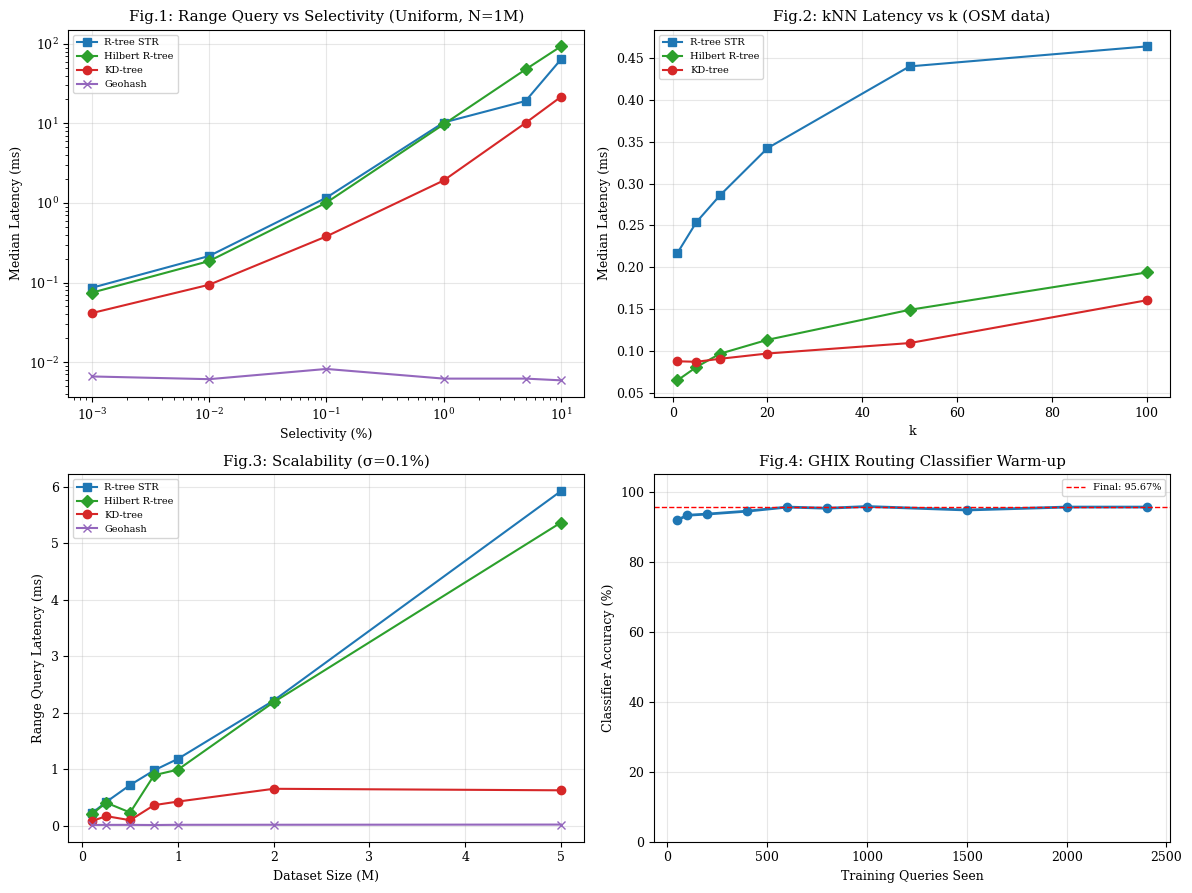

Figures saved as figures.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  CELL 22 — Generate Figures                                         ║
# ╚══════════════════════════════════════════════════════════════════════╝
print('Generating figures...')

COLORS = {'rtree_str':'#1f77b4','hilbert_rtree':'#2ca02c','kdtree':'#d62728',
          'geohash':'#9467bd','hilbert_btree':'#ff7f0e','quadtree':'#8c564b'}
LABELS = {'rtree_str':'R-tree STR','hilbert_rtree':'Hilbert R-tree',
          'kdtree':'KD-tree','geohash':'Geohash',
          'hilbert_btree':'Hilbert B-tree','quadtree':'PR-Quadtree'}
MARKERS = {'rtree_str':'s','hilbert_rtree':'D','kdtree':'o',
           'geohash':'x','hilbert_btree':'^','quadtree':'v'}

sel_x = [float(s.replace('%','')) for s in SEL_LABELS]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# ── Fig 1: Range query latency vs selectivity (Uniform) ──────────────
ax = axes[0,0]
for k in ['rtree_str','hilbert_rtree','kdtree','geohash']:
    if k in RESULTS['exp_B_distributions']['uniform']:
        ys = [RESULTS['exp_B_distributions']['uniform'][k]['range_ms'].get(s,{}).get('med') for s in SEL_LABELS]
        ys = [y for y in ys if y]
        ax.loglog(sel_x[:len(ys)], ys, marker=MARKERS[k], label=LABELS[k], color=COLORS[k], linewidth=1.5)
ax.set_xlabel('Selectivity (%)')
ax.set_ylabel('Median Latency (ms)')
ax.set_title('Fig.1: Range Query vs Selectivity (Uniform, N=1M)')
ax.legend(fontsize=7); ax.grid(True, alpha=0.3)

# ── Fig 2: kNN latency vs k ───────────────────────────────────────────
ax = axes[0,1]
for k in ['rtree_str','hilbert_rtree','kdtree']:
    if k in RESULTS['exp_A_main_table']:
        ys = [RESULTS['exp_A_main_table'][k]['knn_ms'].get(str(kv),{}).get('med') for kv in K_VALUES]
        ys = [y for y in ys if y]
        ax.plot(K_VALUES[:len(ys)], ys, marker=MARKERS[k], label=LABELS[k], color=COLORS[k], linewidth=1.5)
ax.set_xlabel('k'); ax.set_ylabel('Median Latency (ms)')
ax.set_title('Fig.2: kNN Latency vs k (OSM data)')
ax.legend(fontsize=7); ax.grid(True, alpha=0.3)

# ── Fig 3: Scalability ────────────────────────────────────────────────
ax = axes[1,0]
for k in ['rtree_str','hilbert_rtree','kdtree','geohash']:
    xs, ys = [], []
    for n in SCALE_SIZES:
        if str(n) in RESULTS['exp_C_scalability'] and k in RESULTS['exp_C_scalability'][str(n)]:
            xs.append(n/1e6)
            ys.append(RESULTS['exp_C_scalability'][str(n)][k]['rq_0.1pct_ms'])
    if xs:
        ax.plot(xs, ys, marker=MARKERS[k], label=LABELS[k], color=COLORS[k], linewidth=1.5)
ax.set_xlabel('Dataset Size (M)'); ax.set_ylabel('Range Query Latency (ms)')
ax.set_title('Fig.3: Scalability (σ=0.1%)')
ax.legend(fontsize=7); ax.grid(True, alpha=0.3)

# ── Fig 4: GHIX warm-up accuracy curve ───────────────────────────────
ax = axes[1,1]
wu = RESULTS['ghix']['warmup_curve']
ax.plot(wu['n_train'], wu['accuracy_pct'], 'o-', color='#1f77b4', linewidth=2)
ax.axhline(wu['accuracy_pct'][-1], color='red', linestyle='--', linewidth=1, label=f'Final: {wu["accuracy_pct"][-1]}%')
ax.set_xlabel('Training Queries Seen')
ax.set_ylabel('Classifier Accuracy (%)')
ax.set_title('Fig.4: GHIX Routing Classifier Warm-up')
ax.legend(fontsize=7); ax.grid(True, alpha=0.3)
ax.set_ylim([0, 105])

plt.tight_layout()
plt.savefig('figures.png', dpi=180, bbox_inches='tight')
plt.show()
print('Figures saved as figures.png')

try:
    from google.colab import files
    files.download('figures.png')
except: pass